# <center>PyTorch 101</center>
<center> Shan-Hung Wu & DataLab </center>
<center> Fall 2026 </center>

# Why PyTorch?

PyTorch is an open source framework for machine learning. Its tensor operations,
automatic differentiation, and Python-first model definitions support both research
and practical applications. PyTorch has several benefits:
1. Easy model building with `torch.nn`
2. CPU and GPU execution using the same model code
3. Flexible experimentation with eager execution and autograd

We are going to use PyTorch as our framework in the following lectures. In this lab,
you will learn how to install PyTorch and implement a classical deep learning algorithm.


# Environment setup

## Software requirements

This lab requires a 64-bit Python environment with PyTorch, torchvision, NumPy,
Matplotlib, and a Jupyter interface. An NVIDIA GPU is optional; the examples can
also run on CPU. The first MNIST download requires internet access.

## GPU support

To use an NVIDIA GPU, install a compatible NVIDIA driver and a CUDA-enabled
PyTorch build. Prebuilt PyTorch wheels provide the CUDA runtime and cuDNN libraries
needed for this lab; separate CUDA Toolkit or cuDNN installations are not required.

Select your operating system and compute platform on the
[official installation page](https://pytorch.org/get-started/locally/).
After installation, use `torch.cuda.is_available()` to check GPU availability,
as shown in the PyTorch installation check below.

In Jupyter, prefix a shell command with `!` to execute it from a notebook cell.
The following commands provide additional GPU diagnostics.

### Check the NVIDIA driver and GPU status

Use `!nvidia-smi` to check the NVIDIA driver, visible GPUs, memory usage, and
GPU utilization. This diagnostic requires an NVIDIA driver; on a CPU-only
machine, the command may be unavailable and can be skipped.

In [46]:
!nvidia-smi

+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 577.00                 Driver Version: 577.00         CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce GTX  ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   55C    P5             10W /   60W |     573MiB /   6144MiB |     21%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+------------------------+----------------

### Check the CUDA Toolkit compiler

Use `!nvcc --version` to check the installed CUDA Toolkit compiler version.
This can differ from the CUDA runtime bundled with PyTorch. If the CUDA Toolkit
is not installed, the command may be unavailable. A missing `nvcc` does not mean
that PyTorch cannot use the GPU; prebuilt PyTorch wheels do not require it for this lab.

In [45]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2022 NVIDIA Corporation
Built on Wed_Sep_21_10:41:10_Pacific_Daylight_Time_2022
Cuda compilation tools, release 11.8, V11.8.89
Build cuda_11.8.r11.8/compiler.31833905_0


## Tested environment

This notebook was successfully executed in the following 64-bit Conda environment:

- Python 3.12.15
- PyTorch 2.14.1+cu126 and torchvision 0.29.1+cu126
- CUDA 12.6 PyTorch runtime

These are the tested versions, not a list of every supported version.

## Install PyTorch

Install PyTorch and torchvision by following the instructions on the
[official PyTorch installation page](https://pytorch.org/get-started/locally/).
Select the appropriate operating system and compute platform (CPU or CUDA),
then run the installation command provided there inside your Python environment.

Install the other main lab packages with:

```bash
python -m pip install numpy matplotlib jupyterlab
```

The tested versions are listed in the **Tested environment** section above.
If your lab environment is already prepared, skip installation.

Using a virtual environment is recommended. In Jupyter or your IDE, select the
Python kernel for the environment where PyTorch is installed.

Run the following code to check the PyTorch installation and CUDA availability:

In [3]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA runtime in this build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("Num GPUs available:", torch.cuda.device_count())

PyTorch version: 2.14.1+cu126
CUDA runtime in this build: 12.6
CUDA available: True
Num GPUs available: 1


## Google Colab

Google Colab provides a hosted Jupyter environment. Upload this notebook and select
a GPU runtime if one is available. Check `torch.__version__` and
`torchvision.__version__` before running, and restart the runtime after changing packages.

GPU availability, hardware, usage limits, and subscription features vary over time;
do not assume a particular GPU or a fixed session duration. Save your notebook and
outputs before a session ends. Local execution gives you control over the environment.

See [Colab](https://colab.research.google.com/) and the
[PyTorch beginner tutorial](https://docs.pytorch.org/tutorials/beginner/basics/intro.html).

# PyTorch 2 quickstart

PyTorch supplies tensor operations, automatic differentiation, neural network
layers, and optimizers through a Python API. Models execute eagerly by default;

In this lab we will:
- Load MNIST using `torchvision.datasets`
- Build a stack of layers using `nn.Sequential`
- Build a fully customizable model by subclassing `nn.Module`
- Learn the concept of optional model compilation with `torch.compile`
- Customize gradients using `torch.autograd.Function`

## GPU selection and memory allocation

PyTorch allocates CUDA memory on demand and keeps unused allocations in a cache;
there is no memory-growth switch to enable. We use only `cuda:0` when available,
otherwise CPU. To hide other GPUs from the process entirely, set
`CUDA_VISIBLE_DEVICES=0` **before starting the Python kernel**.

An optional `torch.cuda.set_per_process_memory_fraction` limit applies to the
caching allocator, rather than guaranteeing a cap on every allocation in the process.
`torch.cuda.empty_cache()` releases unused cached memory, not live tensors.

In [4]:
import gc
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
# Small dense networks can be slower with excessive CPU threading.
torch.set_num_threads(min(4, torch.get_num_threads()))

In [48]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.set_device(device)
    # Optional allocator limit; uncomment if a shared GPU needs a memory budget:
    # torch.cuda.set_per_process_memory_fraction(0.5, device=device)
    print(torch.cuda.device_count(), "physical GPUs; using", torch.cuda.get_device_name(device))
else:
    print("Using CPU")

1 physical GPUs; using NVIDIA GeForce GTX ... 


## Load datasets via torchvision.datasets

`torchvision.datasets` contains image datasets such as MNIST, CIFAR10, CIFAR100,
and FashionMNIST. Text and tabular datasets can instead be wrapped in a custom
`torch.utils.data.Dataset`; torchvision is specifically for computer vision.

We use MNIST: 60,000 training and 10,000 test grayscale digit images, each
$28\times28$ pixels, initially stored as integers from 0 to 255.

In [6]:
# Helper function
def show_images(image, num_row=2, num_col=5):
    if isinstance(image, torch.Tensor):
        image = image.detach().cpu().numpy()
    fig, axes = plt.subplots(num_row, num_col,
                             figsize=(1.5*num_col, 2*num_row), squeeze=False)
    for i in range(num_row*num_col):
        ax = axes[i//num_col, i%num_col]
        ax.imshow(image[i], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

Load and prepare the MNIST dataset. Convert the samples from integers to floating-point numbers:

In [7]:
mnist_train = datasets.MNIST(root="./data", train=True, download=True)
mnist_test = datasets.MNIST(root="./data", train=False, download=True)
x_train = mnist_train.data.to(torch.float32) / 255.0
x_test = mnist_test.data.to(torch.float32) / 255.0
y_train = mnist_train.targets.to(torch.long)
y_test = mnist_test.targets.to(torch.long)

Training data: torch.Size([60000, 28, 28])
Test data: torch.Size([10000, 28, 28])


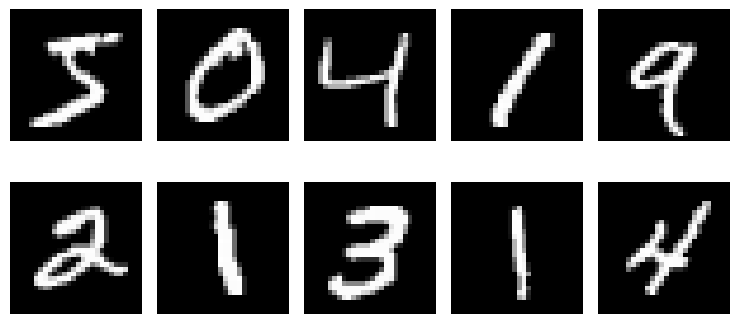

In [8]:
print("Training data: {}".format(x_train.shape))
print("Test data: {}".format(x_test.shape))
show_images(x_train)

## Build model via Sequential API
### When to use?
`nn.Sequential` fits a plain stack of layers in which each layer passes its output
to the next. We retain the original architecture: Flatten → Linear(128) → ReLU →
Dropout(0.2) → Linear(10). The final layer returns logits.

In [9]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(128, 10),
).to(device)

For each example, the model returns a vector of unnormalized scores called logits, one for each class. Softmax converts these scores into class probabilities. In multiclass classification, an individual logit is not the log-odds of that class versus all other classes; the difference between two logits equals the log ratio of their softmax probabilities: $z_i-z_j=\log(p_i/p_j)$.

In [10]:
model.eval()  
with torch.no_grad():
    predictions = model(x_train[:1].to(device))
predictions.cpu().numpy()

array([[ 0.0981975 , -0.04340161, -0.01518833, -0.0362507 , -0.21002297,
         0.02741192, -0.00670645,  0.00367521,  0.10945357,  0.10933366]],
      dtype=float32)

The `torch.softmax` function converts logits to class probabilities along the last dimension:

In [11]:
torch.softmax(predictions, dim=-1).cpu().numpy()

array([[0.10947957, 0.09502488, 0.09774403, 0.09570684, 0.08044047,
        0.10199791, 0.09857661, 0.09960532, 0.11071883, 0.11070556]],
      dtype=float32)

Keep the final layer as logits when using `nn.CrossEntropyLoss`. This loss combines
log-softmax with negative log likelihood in a numerically stable way. Adding softmax
before this loss would change the calculation.

The loss takes **logits first, integer labels second**. Labels use `torch.long`;
the default reduction averages over the batch (`reduction="none"` gives per-example losses).

In [12]:
loss_fn = nn.CrossEntropyLoss()

This loss is the negative log probability of the true class. For a model that
assigns roughly $1/10$ to every class, the loss is near $-\log(1/10)\approx2.3$.

In [13]:
loss_fn(predictions, y_train[:1].to(device)).item()

2.2828030586242676

In [14]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, eps=1e-7)

`print(model)` displays the registered layers. `model.parameters()` provides the
parameters used by the optimizer and lets us count trainable parameters:

In [15]:
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


### Training with `model.train()` and autograd

`model.train()` selects training behavior, including enabling Dropout. It does not
train the model by itself. For each batch, clear previous gradients, compute logits
and loss, call `loss.backward()`, then update parameters with `optimizer.step()`.

Train for five epochs with batch size 32. `TensorDataset` pairs images with labels;
`DataLoader` shuffles and batches those pairs. Accumulate loss and accuracy for
each epoch, and keep a history of the results.

In [16]:
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=32,
                          shuffle=True, num_workers=0,
                          pin_memory=(device.type == "cuda"))

history = {"loss": [], "accuracy": []}

for epoch in range(5):
    model.train()
    total_loss, correct, count = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()

        count += labels.numel()
        total_loss += loss.item() * labels.numel()
        correct += (logits.detach().argmax(dim=1) == labels).sum().item()

    history["loss"].append(total_loss / count)
    history["accuracy"].append(correct / count)
    print(f"Epoch {epoch+1}/5, Loss: {total_loss/count:.4f}, Accuracy: {correct/count:.4f}")

Epoch 1/5, Loss: 0.3252, Accuracy: 0.9076


Epoch 2/5, Loss: 0.1540, Accuracy: 0.9544


Epoch 3/5, Loss: 0.1111, Accuracy: 0.9664


Epoch 4/5, Loss: 0.0912, Accuracy: 0.9720


Epoch 5/5, Loss: 0.0776, Accuracy: 0.9754


### Evaluation with `model.eval()` and `torch.no_grad()`

`model.eval()` selects evaluation behavior, disabling Dropout in this model.
It does not calculate scores or disable gradient recording by itself.
`torch.no_grad()` disables gradient recording while we calculate test logits,
loss, and accuracy. Weight each batch's mean loss by its size so a smaller final
batch contributes correctly to the overall mean.

In [17]:
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=32,
                         num_workers=0, pin_memory=(device.type == "cuda"))

model.eval()
total_loss, correct, count = 0.0, 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = loss_fn(logits, labels)
        count += labels.numel()
        total_loss += loss.item() * labels.numel()
        correct += (logits.argmax(dim=1) == labels).sum().item()

test_scores = (total_loss / count, correct / count)
print(f"Test loss: {test_scores[0]:.4f}, Test accuracy: {test_scores[1]:.4f}")

Test loss: 0.0799, Test accuracy: 0.9760


This architecture typically reaches roughly 97–98% MNIST test accuracy. The exact result depends on initialization, shuffling, hardware, and training.

In [18]:
# Release the old model and optimizer before creating the next model.
del model, optimizer
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()

## Build model via Model Subclassing
### When to use?
Subclassing `nn.Module` gives full control over the forward pass. This is useful
for custom architectures, dynamic control flow, and research experiments.
Unlike `nn.Sequential`, which connects layers in order, a custom module defines
its own `forward` method and can express branches, shared layers, or multiple
inputs and outputs.

We keep the same network architecture as the Sequential example and organize the
training/evaluation operations learned above into reusable `train_step` and
`test_step` functions with metric accumulation.

Use `TensorDataset` and `DataLoader` to batch and shuffle the dataset:

In [19]:
train_ds = DataLoader(TensorDataset(x_train, y_train), batch_size=32,
                      shuffle=True, num_workers=0,
                      pin_memory=(device.type == "cuda"))
test_ds = DataLoader(TensorDataset(x_test, y_test), batch_size=32,
                     num_workers=0, pin_memory=(device.type == "cuda"))

Build the PyTorch model by subclassing `nn.Module` and defining `forward`:

In [20]:
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.dropout = nn.Dropout(0.2)
        self.d1 = nn.Linear(28 * 28, 128)
        self.d2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.d1(x))
        x = self.dropout(x)
        return self.d2(x)

In [21]:
# Parameters are initialized in __init__; a separate build() call is unnecessary.
model = MyModel().to(device)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MyModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dropout): Dropout(p=0.2, inplace=False)
  (d1): Linear(in_features=784, out_features=128, bias=True)
  (d2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


Choose an optimizer and loss function for training.

In [22]:
loss_object = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, eps=1e-7)

Track loss, the number of correct predictions, and the number of samples using
ordinary Python numbers. Add each batch's loss multiplied by its size, then divide
by the total sample count at the end of the epoch. Accuracy is the total number of
correct predictions divided by the total sample count. This also handles a smaller
final batch correctly; no custom metric class is needed.

In [23]:
# Initialize scalar accumulators; reset them at the start of every epoch below.
train_loss, train_correct, train_count = 0.0, 0, 0
test_loss, test_correct, test_count = 0.0, 0, 0

The earlier training loop used PyTorch autograd to compute gradients with
`loss.backward()`, then updated parameters with `optimizer.step()`.
Each parameter's `.grad` stores its derivative:

$$\frac{\partial L}{\partial W_{i,j}}$$

Now organize those same operations into a reusable `train_step` function, and
evaluation into a `test_step` function. These are teaching helpers we define here,
not built-in model methods. Each step returns the batch's summed loss, number of
correct predictions, and sample count; the epoch loop accumulates those values.

See [Autograd basics](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).

In [24]:
def train_step(images, labels):
    model.train()
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad(set_to_none=True)
    predictions = model(images)
    loss = loss_object(predictions, labels)
    loss.backward()
    optimizer.step()

    count = labels.numel()
    correct = (predictions.detach().argmax(dim=1) == labels).sum().item()
    return loss.item() * count, correct, count

In [25]:
@torch.no_grad()
def test_step(images, labels):
    model.eval()
    images, labels = images.to(device), labels.to(device)
    predictions = model(images)
    loss = loss_object(predictions, labels)

    count = labels.numel()
    correct = (predictions.argmax(dim=1) == labels).sum().item()
    return loss.item() * count, correct, count

The next epoch loop resets the scalar totals, calls these reusable steps, and
adds up their results. Divide the loss and correct-prediction totals by the sample
count to report the epoch's mean loss and accuracy.

These steps execute eagerly. The next optional section introduces the concept of
model compilation; it does not add another training implementation.

In [26]:
EPOCHS = 5

for epoch in range(EPOCHS):
    train_loss, train_correct, train_count = 0.0, 0, 0
    test_loss, test_correct, test_count = 0.0, 0, 0

    for images, labels in train_ds:
        batch_loss, batch_correct, batch_count = train_step(images, labels)
        train_loss += batch_loss
        train_correct += batch_correct
        train_count += batch_count

    for images, labels in test_ds:
        batch_loss, batch_correct, batch_count = test_step(images, labels)
        test_loss += batch_loss
        test_correct += batch_correct
        test_count += batch_count

    train_accuracy = train_correct / train_count
    test_accuracy = test_correct / test_count
    print(f"Epoch {epoch+1}, Loss: {train_loss/train_count:.4f}, "
          f"Accuracy: {train_accuracy*100:.4f}, "
          f"Test Loss: {test_loss/test_count:.4f}, "
          f"Test Accuracy: {test_accuracy*100:.4f}")

Epoch 1, Loss: 0.3253, Accuracy: 90.7450, Test Loss: 0.1645, Test Accuracy: 95.1600


Epoch 2, Loss: 0.1562, Accuracy: 95.3917, Test Loss: 0.1182, Test Accuracy: 96.3600


Epoch 3, Loss: 0.1149, Accuracy: 96.5850, Test Loss: 0.0895, Test Accuracy: 97.2900


Epoch 4, Loss: 0.0932, Accuracy: 97.0967, Test Loss: 0.0818, Test Accuracy: 97.4900


Epoch 5, Loss: 0.0797, Accuracy: 97.5533, Test Loss: 0.0764, Test Accuracy: 97.7400


### Sequential API and Model Subclassing

| Style | Composition | Best fit |
| --- | --- | --- |
| `nn.Sequential` | Ordered modules with an automatic forward pass | Simple stacks of layers |
| Subclassing `nn.Module` | Layers registered in `__init__`, operations defined in `forward` | Custom architectures, branches, and dynamic behavior |

These approaches interoperate: a custom module can contain a Sequential module.
Both models above have the same layer sizes, dropout rate, and 101,770 trainable
parameters. Their training and evaluation use the same PyTorch operations.

`torch.nn.functional` supplies operations such as `F.relu` that can be used inside
`forward`; it is not a separate model-building API.

## Optional: Introduction to `torch.compile`

PyTorch normally executes tensor operations eagerly. `torch.compile` can capture
the operations in a model and pass its computation graph to an optimizing backend,
which may combine operations and reduce execution overhead. This can improve
training or inference speed without requiring a different model architecture.

The first execution has compilation overhead. Actual performance depends on the
model, batch size, hardware, and backend, so compilation does not guarantee a
speedup. Small models can be slower, and backend/compiler support must be checked
for the execution environment.

`torch.compile` is an optional performance tool, not a requirement for model
training. This introductory lab covers the concept only; implementation and fair
performance measurement are left to a later, advanced lesson.

See [torch.compile](https://docs.pytorch.org/docs/2.14/generated/torch.compile.html)
and the [end-to-end model compilation tutorial](https://docs.pytorch.org/tutorials/intermediate/torch_compile_full_example.html).


## Customize gradient flow with torch.autograd.Function

Subclass `torch.autograd.Function` and define static `forward` and `backward`
methods to provide a custom derivative. Invoke the operation using `.apply`.
This provides control over the backward computation, for example to improve
numerical stability.

Consider the softplus function used in likelihood calculations:
$$y=\log_e(1+e^x)$$

In [30]:
def log1pexp(x):
    return torch.log(1 + torch.exp(x))

The derivative is:
$$\frac{dy}{dx}=\frac{e^x}{1+e^x}=1-\frac{1}{1+e^x}$$

At $x=100$ it should be approximately 1. With float32, the naive exponential
overflows: the forward value is infinity and its automatically computed gradient
is NaN. We explicitly use float32 to demonstrate this behavior.

In [31]:
x = torch.tensor(100., dtype=torch.float32, requires_grad=True)
y = log1pexp(x)
dy, = torch.autograd.grad(y, x)
print("y =", y.item())
print("dy/dx =", dy.item())  # NaN
assert torch.isnan(dy)

y = inf
dy/dx = nan


The derivative is sigmoid(x), which can be evaluated stably. We also stabilize the
forward calculation with `logaddexp(0, x)` so neither the output nor the gradient
overflows. For ordinary applications, `F.softplus` already supplies a stable implementation.

In [32]:
class Log1pExp(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.logaddexp(torch.zeros_like(x), x)

    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        return grad_output * torch.sigmoid(x)

def log1pexp(x):
    return Log1pExp.apply(x)

In [33]:
x = torch.tensor(100., dtype=torch.float32, requires_grad=True)
y = log1pexp(x)
dy, = torch.autograd.grad(y, x)
print("y =", y.item())
print("dy/dx =", dy.item())  # 1.0
assert torch.isfinite(y) and dy.item() == 1.0

y = 100.0
dy/dx = 1.0


# Reference
- [PyTorch](https://pytorch.org/)
- [Version pairs and CPU/CUDA installation commands](https://pytorch.org/get-started/previous-versions/)
- [PyTorch beginner tutorial](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)
- [torch.nn](https://docs.pytorch.org/docs/2.8/nn.html)
- [torchvision datasets](https://docs.pytorch.org/vision/0.23/datasets.html)
- [torch.compile](https://docs.pytorch.org/docs/2.8/generated/torch.compile.html)
- [Extending autograd](https://docs.pytorch.org/docs/2.8/notes/extending.html)